In [6]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

import pandas as pd

np.random.seed(42)
random.seed(42)

class SISModel:
    def __init__(self, N, populations, beta, mu, p, timesteps, initial_infected, alpha, average_degree):
        self.N = N
        self.populations = populations  # 每个patch的人口不同
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.timesteps = timesteps
        self.initial_infected = initial_infected
        self.average_degree = average_degree

        # 创建包含不同人口数量的patch
        self.patches = [np.zeros(self.populations[i]) for i in range(N)]
        self.infection_history = np.zeros((timesteps, N))
        self.total_infected_history = np.zeros(timesteps)  # 记录每个时间步的总感染人数
        self.total_susceptible_history = np.zeros(timesteps)  # 记录每个时间步的总易感人数

        # 生成具有给定平均度的Barabasi-Albert网络
        self.G = nx.barabasi_albert_graph(N, 5)

        # 为每条边分配1到10之间的随机权重
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

        self.rho = np.zeros(N)
        self._initialize_patches()

    def _initialize_patches(self):
        # 每个patch初始感染人数为10
        for i in range(self.N):
            infected_indices = np.random.choice(self.populations[i], self.initial_infected, replace=False)
            self.patches[i][infected_indices] = 1
            self.rho[i] = np.sum(self.patches[i]) / self.populations[i]

    def _get_Pi_i(self):
        R_i = np.zeros(self.N)
        D_i = np.zeros(self.N)
        P_i = np.zeros(self.N)
        Pi_i = np.zeros(self.N)
        new_rho = np.zeros(self.N)
        for i in range(self.N):
            R_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * self.rho[i] +
                                             np.sum([self.p * self.C[j, i] * self.average_degree * self.rho[j] for j in range(self.N)]))
            D_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.populations[i] * self.rho[i] +
                                             np.sum([self.p * self.C[j, i] * self.populations[j] * self.rho[j] for j in range(self.N)]))
            P_i[i] = self.alpha * R_i[i] + (1 - self.alpha) * D_i[i]
        for i in range(self.N):
            Pi_i[i] = (1 - self.p) * P_i[i] + self.p * np.sum([self.C[i, j] * P_i[j] for j in range(self.N)])
            new_rho[i] = (1 - self.mu) * self.rho[i] + (1 - self.rho[i]) * Pi_i[i]
        self.Pi_i = Pi_i
        self.rho = new_rho

    def _infection_process(self, patch_index, current_patch):
        for j in range(len(current_patch)):
            if current_patch[j] == 0 and np.random.rand() < self.Pi_i[patch_index]:
                current_patch[j] = 1
        return current_patch

    def _recovery_process(self, current_patch):
        for j in range(len(current_patch)):
            if current_patch[j] == 1 and np.random.rand() < self.mu:
                current_patch[j] = 0
        return current_patch

    def run_simulation(self):
        for t in range(self.timesteps):
            self._get_Pi_i()
            total_infected = 0  # 记录当前时间步的总感染人数
            total_susceptible = 0  # 记录当前时间步的总易感人数
            for i in range(self.N):
                current_patch = self.patches[i]
                current_patch = self._infection_process(i, current_patch)
                current_patch = self._recovery_process(current_patch)
                self.patches[i] = current_patch
                self.infection_history[t, i] = np.sum(current_patch)
                total_infected += np.sum(current_patch)
                total_susceptible += len(current_patch) - np.sum(current_patch)  # 易感人数
            self.total_infected_history[t] = total_infected  # 记录总感染人数
            self.total_susceptible_history[t] = total_susceptible  # 记录总易感人数

# 参数设置
N = 50
population_per_patch = np.full(N, 100)
mu = 0.1
p = 0.6
timesteps = 500
initial_infected = 5
alpha = 0.6
average_degrees = [10, 15, 20]
betas = [0.001608, 0.00402]  # 两个不同的beta值
num_simulations = 50  # 模拟次数

# 针对不同平均度和不同beta运行模拟并记录结果
all_results = []

for beta in betas:
    for avg_degree in average_degrees:
        degree_results_infected = np.zeros((num_simulations, timesteps))
        degree_results_susceptible = np.zeros((num_simulations, timesteps))
        for sim in range(num_simulations):
            model = SISModel(N=N, populations=population_per_patch, beta=beta, mu=mu, p=p, timesteps=timesteps, 
                             initial_infected=initial_infected, alpha=alpha, average_degree=avg_degree)
            model.run_simulation()
            degree_results_infected[sim, :] = model.total_infected_history
            degree_results_susceptible[sim, :] = model.total_susceptible_history
        avg_infected = np.mean(degree_results_infected, axis=0)
        avg_susceptible = np.mean(degree_results_susceptible, axis=0)
        # 将beta, avg_degree, avg_infected, avg_susceptible 作为一行展开放入
        all_results.append([beta, avg_degree] + avg_infected.tolist() + avg_susceptible.tolist())

# 创建包含 timesteps 列的 DataFrame
columns = ['beta', 'avg_degree'] + [f'infected_timestep_{i}' for i in range(timesteps)] + [f'susceptible_timestep_{i}' for i in range(timesteps)]
all_results_df = pd.DataFrame(all_results, columns=columns)

# 保存结果为 CSV
all_results_df.to_csv('./BAdata/BAresults_final.csv', index=False)


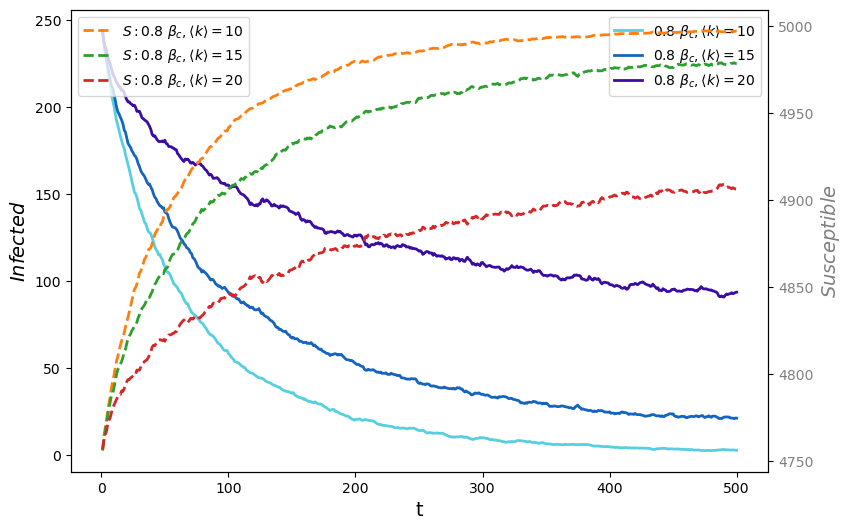

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# 读取保存的结果
all_results = pd.read_csv('./BAdata/BAresults_final.csv')

# 获取时间步长
timesteps = len([col for col in all_results.columns if 'infected_timestep_' in col])

# 使用 arange 从 1 到 timesteps 确保 x 轴从1开始
time_range = np.arange(1, timesteps + 1)

# 创建一个图形对象，分别绘制感染人数和易感人数
fig, ax1 = plt.subplots(figsize=(9, 6))

# 提取不同组合的感染人数时间序列数据并绘制曲线
sns.lineplot(
    ax=ax1,
    x=time_range,
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 10), [f'infected_timestep_{i}' for i in range(timesteps)]].values.flatten(),
    linewidth=2,
    color='#56cfe1',
    label=r'$0.8\ \beta_{c}, \langle k \rangle=10$'
)

sns.lineplot(
    ax=ax1,
    x=time_range,
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 15), [f'infected_timestep_{i}' for i in range(timesteps)]].values.flatten(),
    linewidth=2,
    color='#1565c0',
    label=r'$0.8\ \beta_{c}, \langle k \rangle=15$'
)

sns.lineplot(
    ax=ax1,
    x=time_range,
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 20), [f'infected_timestep_{i}' for i in range(timesteps)]].values.flatten(),
    linewidth=2,
    color='#3a0ca3',
    label=r'$0.8\ \beta_{c}, \langle k \rangle=20$'
)

# 设置对数刻度和标签
ax1.set_xlabel('t', fontsize=14)
# ax1.set_xscale('log')
ax1.set_ylabel(r'$Infected$', fontsize=14, color='black')
ax1.tick_params(axis='y', labelcolor='black')

# 共享x轴，在同一图中绘制易感人数曲线
ax2 = ax1.twinx()

# 提取不同组合的易感人数时间序列数据并绘制曲线（假设已有 susceptible 数据）
sns.lineplot(
    ax=ax2,
    x=time_range,
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 10), [f'susceptible_timestep_{i}' for i in range(timesteps)]].values.flatten(),
    linewidth=2,
    color='#ff7f0e',
    linestyle='--',
    label=r'$S: 0.8\ \beta_{c}, \langle k \rangle=10$'
)

sns.lineplot(
    ax=ax2,
    x=time_range,
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 15), [f'susceptible_timestep_{i}' for i in range(timesteps)]].values.flatten(),
    linewidth=2,
    color='#2ca02c',
    linestyle='--',
    label=r'$S: 0.8\ \beta_{c}, \langle k \rangle=15$'
)

sns.lineplot(
    ax=ax2,
    x=time_range,
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 20), [f'susceptible_timestep_{i}' for i in range(timesteps)]].values.flatten(),
    linewidth=2,
    color='#d62728',
    linestyle='--',
    label=r'$S: 0.8\ \beta_{c}, \langle k \rangle=20$'
)

# 设置易感人数的 y 轴标签和颜色
ax2.set_ylabel(r'$Susceptible$', fontsize=14, color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

# 设置图例
# fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax1.transAxes)

# 保存和展示图像
plt.savefig('infected_vs_susceptible.pdf', dpi=300, bbox_inches='tight')
plt.show()
